In [1]:
import pandas as pd

In [3]:
url = "/content/recreio_nas_ferias_dados_sinteticos_2026.csv"

In [4]:
base = pd.read_csv(url, sep = ',')

In [5]:
base.head()

,ID_INSCRICAO,ID_ALUNO,GENERO,IDADE,DATA,HORARIO,ATIVIDADE,DESCRICAO_ATIVIDADE
0,INS0001,ALU0001,Masculino,14,2026-01-07,09:00,Vôlei,Vôlei recreativo
1,INS0002,ALU0002,Masculino,14,2026-01-07,09:00,Vôlei,Fundamentos do vôlei
2,INS0003,ALU0003,Feminino,8,2026-01-07,09:00,Tênis de mesa,Desafios de pingue-pongue
3,INS0004,ALU0004,Masculino,12,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
4,INS0005,ALU0005,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Oficina de desenho


In [7]:
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14420 entries, 0 to 14419
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID_INSCRICAO         14420 non-null  object
 1   ID_ALUNO             14420 non-null  object
 2   GENERO               14420 non-null  object
 3   IDADE                14420 non-null  int64 
 4   DATA                 14420 non-null  object
 5   HORARIO              14420 non-null  object
 6   ATIVIDADE            14420 non-null  object
 7   DESCRICAO_ATIVIDADE  14420 non-null  object
dtypes: int64(1), object(7)
memory usage: 901.4+ KB


Quantas participações nas atividades existem em cada idade?

In [10]:
base["IDADE"].value_counts()

,count
IDADE,
10,1908
9,1876
8,1720
11,1676
12,1448
7,1272
13,1156
14,1032
6,1024


In [8]:
base.columns

Index(['ID_INSCRICAO', 'ID_ALUNO', 'GENERO', 'IDADE', 'DATA', 'HORARIO',
       'ATIVIDADE', 'DESCRICAO_ATIVIDADE'],
      dtype='object')

In [16]:
#Idades distintas
base["IDADE"].nunique()

11

Quantas crianças distintas temos em cada idade?

In [17]:
base.groupby("IDADE")

Contando os Alunos Distintos

In [18]:
base.groupby("IDADE")["ID_ALUNO"].nunique()

,ID_ALUNO
IDADE,
4,12
5,15
6,21
7,27
8,36
9,39
10,39
11,36
12,30


### Outro jeito didático
com separação

In [19]:
grupos = base.groupby("IDADE")# Agrupa os registros do DataFrame por idade.

In [20]:
resultado = grupos["ID_ALUNO"].nunique() #Conta a quantidade de identificadores distintos (ID_ALUNO) dentro de cada agrupamento.

In [26]:
#Quantidade: quantos alunos temos em cada idade?
resultado

,ID_ALUNO
IDADE,
4,12
5,15
6,21
7,27
8,36
9,39
10,39
11,36
12,30


In [22]:
#total de alunos
resultado.sum()

np.int64(300)

In [27]:
# Percentual: qual a participação de cada idade no total?
percentual = resultado/resultado.sum() *100
percentual.round(2) # é também a frequencia relativa

,ID_ALUNO
IDADE,
4,4.0
5,5.0
6,7.0
7,9.0
8,12.0
9,13.0
10,13.0
11,12.0
12,10.0


## Visualização gráfica

<Axes: title={'center': 'Distribuição de alunos por idade'}, xlabel='Idade (anos)', ylabel='Quantidade de alunos'>

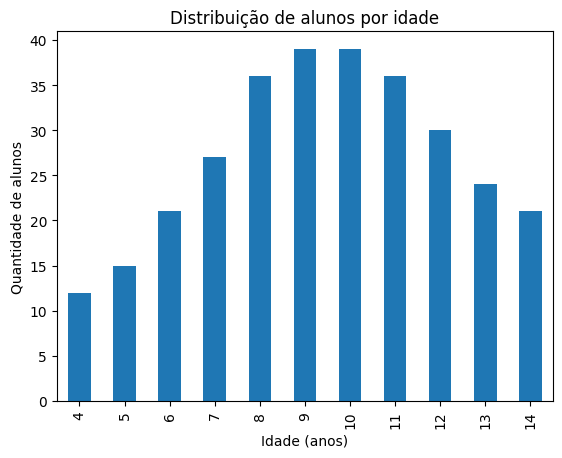

In [38]:
resultado.sort_index().plot.bar(
 xlabel = "Idade (anos)",
 ylabel = "Quantidade de alunos",
 title = "Distribuição de alunos por idade"
)

<Axes: title={'center': 'Distribuição Percentual de alunos por idade'}, xlabel='Idade (anos)', ylabel='Participação(%)'>

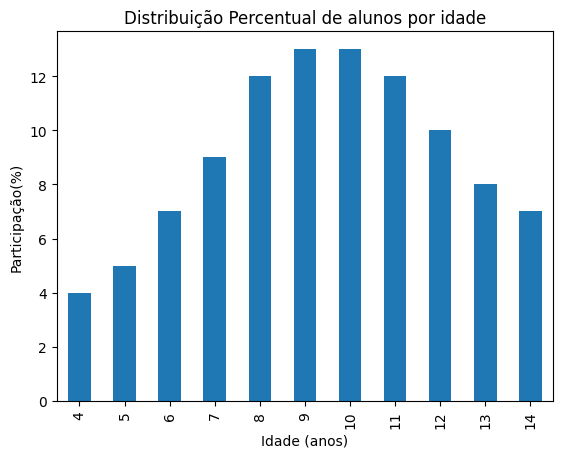

In [39]:
percentual.sort_index().plot.bar(
  xlabel="Idade (anos)" ,
  ylabel ="Participação(%)" ,
  title = "Distribuição Percentual de alunos por idade",
)

## Análise de Genero

In [41]:
base["GENERO"].value_counts()# ocorrências de generos que não são distintos

,count
GENERO,
Masculino,7408
Feminino,7012


In [45]:
genero = base.groupby("GENERO")["ID_ALUNO"].nunique()

Lembre-se:  Agrupar > Selecionar > Agregar

groupby("GENERO") → agrupa por gênero.



["ID_ALUNO"] → seleciona a coluna dos identificadores.



.nunique() → conta os identificadores únicos em cada grupo.

In [46]:
percentual_genero = genero / genero.sum()*100

In [49]:
# Percentual de participantes por Gênero
percentual_genero.round(2)

,ID_ALUNO
GENERO,
Feminino,48.67
Masculino,51.33


<Axes: title={'center': 'Distribuição percentual por gênero'}, xlabel='Gênero', ylabel='Particição(%)'>

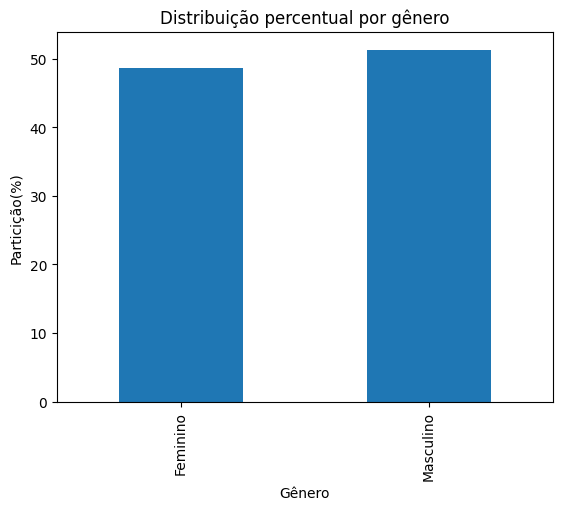

In [47]:
percentual_genero.plot.bar(
    xlabel = "Gênero",
    ylabel = "Particição(%)",
    title = "Distribuição percentual por gênero"



)

## Medias de Tendencias Centrais(média, mediana e moda)

### Média

In [50]:
base["IDADE"].mean()

np.float64(9.432177531206657)

In [51]:
round(float(base["IDADE"].mean()), 2)


9.43

In [52]:
media = base["IDADE"].mean()

print(f"{media:.2f} anos")

9.43 anos


### Mediana

In [55]:
mediana = base["IDADE"].median()
print(f"Idade mediana dos participantes: {mediana:.0f} anos")

Idade mediana dos participantes: 10 anos


### Moda

In [58]:
moda = base["IDADE"].mode()
print(f"Idade mais frequente: {moda.iloc[0]} anos")

Idade mais frequente: 10 anos
